بررسی ساختار دیتاست 


In [44]:
from huggingface_hub import HfApi
from huggingface_hub.hf_api import RepoFile, RepoFolder
from collections import Counter
from pathlib import PurePosixPath
import pandas as pd

# ==========================================
# 1. Dataset Configuration
# ==========================================

REPO_ID = "nexar-ai/nexar_collision_prediction"

api = HfApi()

# ==========================================
# 2. Get Repository Structure
# ==========================================

print("Fetching dataset structure...")

items = list(api.list_repo_tree(
    repo_id=REPO_ID,
    repo_type="dataset",
    recursive=True
))

# Separate files and folders
repo_files = [
    f for f in items
    if isinstance(f, RepoFile)
]

repo_folders = [
    f for f in items
    if isinstance(f, RepoFolder)
]

print("\n========== DATASET INFORMATION ==========")

print("Repository:", REPO_ID)
print("Total files:", len(repo_files))
print("Total folders:", len(repo_folders))

# ==========================================
# 3. Folder Structure
# ==========================================

print("\n========== FOLDER STRUCTURE ==========")

for folder in sorted(repo_folders, key=lambda x: x.path):
    depth = folder.path.count("/")

    if depth <= 2:
        print("  " * depth + folder.path)

# ==========================================
# 4. File Format Distribution
# ==========================================

extensions = Counter(
    PurePosixPath(f.path).suffix.lower()
    for f in repo_files
)

print("\n========== FILE FORMATS ==========")

for ext, count in sorted(extensions.items()):
    print(f"{ext or '[no extension]'}: {count}")

# ==========================================
# 5. Create File Inventory
# ==========================================

inventory = pd.DataFrame([
    {
        "path": f.path,
        "type": "file",
        "extension": PurePosixPath(f.path).suffix.lower(),
        "size_mb": (
            round(f.size / (1024**2), 2)
            if f.size is not None else None
        )
    }
    for f in repo_files
])

print("\n========== FILE INVENTORY ==========")

display(inventory.head(20))

# ==========================================
# 6. Video Distribution
# ==========================================

video_extensions = {".mp4", ".avi", ".mov", ".mkv"}

videos = inventory[
    inventory["extension"].isin(video_extensions)
].copy()

videos["folder"] = videos["path"].apply(
    lambda x: str(PurePosixPath(x).parent)
)

print("\n========== VIDEO DISTRIBUTION ==========")

video_distribution = (
    videos.groupby("folder")
    .size()
    .reset_index(name="video_count")
)

display(video_distribution)

print("Total videos:", len(videos))

# ==========================================
# 7. Dataset Size
# ==========================================

print("\n========== DATASET SIZE ==========")

total_size_gb = inventory["size_mb"].sum() / 1024
video_size_gb = videos["size_mb"].sum() / 1024

print(f"Total dataset size: {total_size_gb:.2f} GB")
print(f"Total video size: {video_size_gb:.2f} GB")

unknown_sizes = inventory["size_mb"].isna().sum()

if unknown_sizes:
    print(f"Warning: {unknown_sizes} files have unknown sizes.")

# ==========================================
# 8. Metadata Files
# ==========================================

print("\n========== METADATA FILES ==========")

metadata_files = inventory[
    inventory["path"].str.contains(
        r"metadata|\.csv$",
        case=False,
        regex=True
    )
]

display(metadata_files)

# ==========================================
# 9. Sample Video Files
# ==========================================

print("\n========== SAMPLE VIDEOS ==========")

display(
    videos[["path", "size_mb", "folder"]].head(10)
)

# ==========================================
# 10. Summary
# ==========================================

print("\n========== FINAL SUMMARY ==========")

print("Total files:", len(repo_files))
print("Total folders:", len(repo_folders))
print("Total videos:", len(videos))
print("Metadata/CSV files:", len(metadata_files))
print("Dataset size (GB):", round(total_size_gb, 2))

print("\n========== INSPECTION COMPLETED ==========")

Fetching dataset structure...

========== DATASET INFORMATION ==========
Repository: nexar-ai/nexar_collision_prediction
Total files: 2857
Total folders: 9

========== FOLDER STRUCTURE ==========
test-private
  test-private/negative
  test-private/positive
test-public
  test-public/negative
  test-public/positive
train
  train/negative
  train/positive

========== FILE FORMATS ==========
[no extension]: 2
.csv: 9
.md: 1
.mp4: 2844
.py: 1

========== FILE INVENTORY ==========


,path,type,extension,size_mb
0,.gitattributes,file,,0.00
1,LICENSE,file,,0.00
2,README.md,file,.md,0.00
3,evaluate_submission.py,file,.py,0.00
4,sample_submission.csv,file,.csv,0.03
5,solution.csv,file,.csv,0.02
6,test-private/negative/01047.mp4,file,.mp4,2.60
7,test-private/negative/01053.mp4,file,.mp4,4.79
8,test-private/negative/01055.mp4,file,.mp4,5.33
9,test-private/negative/01057.mp4,file,.mp4,5.33



========== VIDEO DISTRIBUTION ==========


,folder,video_count
0,test-private/negative,339
1,test-private/positive,338
2,test-public/negative,333
3,test-public/positive,334
4,train/negative,750
5,train/positive,750


Total videos: 2844

========== DATASET SIZE ==========
Total dataset size: 29.22 GB
Total video size: 29.22 GB

========== METADATA FILES ==========


,path,type,extension,size_mb
4,sample_submission.csv,file,.csv,0.03
5,solution.csv,file,.csv,0.02
345,test-private/negative/metadata.csv,file,.csv,0.01
684,test-private/positive/metadata.csv,file,.csv,0.02
1018,test-public/negative/metadata.csv,file,.csv,0.01
1353,test-public/positive/metadata.csv,file,.csv,0.02
1354,time_to_accident_test_map.csv,file,.csv,0.01
2105,train/negative/metadata.csv,file,.csv,0.02
2856,train/positive/metadata.csv,file,.csv,0.03



========== SAMPLE VIDEOS ==========


,path,size_mb,folder
6,test-private/negative/01047.mp4,2.60,test-private/negative
7,test-private/negative/01053.mp4,4.79,test-private/negative
8,test-private/negative/01055.mp4,5.33,test-private/negative
9,test-private/negative/01057.mp4,5.33,test-private/negative
10,test-private/negative/01063.mp4,5.29,test-private/negative
11,test-private/negative/01064.mp4,3.31,test-private/negative
12,test-private/negative/01077.mp4,2.36,test-private/negative
13,test-private/negative/01082.mp4,3.30,test-private/negative
14,test-private/negative/01086.mp4,2.89,test-private/negative
15,test-private/negative/01087.mp4,2.20,test-private/negative



========== FINAL SUMMARY ==========
Total files: 2857
Total folders: 9
Total videos: 2844
Metadata/CSV files: 9
Dataset size (GB): 29.22

========== INSPECTION COMPLETED ==========


دریافت متادیتا 

In [45]:
from huggingface_hub import HfApi, hf_hub_download
from pathlib import Path
import pandas as pd

# 1. Configuration
REPO_ID = "nexar-ai/nexar_collision_prediction"
SAVE_DIR = Path("data/metadata")

SAVE_DIR.mkdir(parents=True, exist_ok=True)

api = HfApi()

# 2. Find metadata files
repo_files = api.list_repo_files(
    repo_id=REPO_ID,
    repo_type="dataset"
)

metadata_files = [
    path for path in repo_files
    if Path(path).name.lower() == "metadata.csv"
]

print("Metadata files found:", len(metadata_files))
print(*metadata_files, sep="\n")

# 3. Download and read metadata
metadata_dfs = {}

for file_path in metadata_files:

    local_path = hf_hub_download(
        repo_id=REPO_ID,
        repo_type="dataset",
        filename=file_path,
        local_dir=SAVE_DIR
    )

    df = pd.read_csv(local_path)
    metadata_dfs[file_path] = df

    print(f"\n========== {file_path} ==========")

    print("Shape:", df.shape)
    print("\nColumns:", df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nFirst 5 Rows:")
    display(df.head())

print("\nMetadata download completed!")
print("Saved in:", SAVE_DIR.resolve())

Metadata files found: 6
test-private/negative/metadata.csv
test-private/positive/metadata.csv
test-public/negative/metadata.csv
test-public/positive/metadata.csv
train/negative/metadata.csv
train/positive/metadata.csv

========== test-private/negative/metadata.csv ==========
Shape: (339, 7)

Columns: ['file_name', 'time_of_event', 'time_of_alert', 'light_conditions', 'weather', 'scene', 'time_to_accident']

Data Types:
file_name               str
time_of_event       float64
time_of_alert       float64
light_conditions        str
weather                 str
scene                   str
time_to_accident    float64
dtype: object

Missing Values:
file_name             0
time_of_event       339
time_of_alert       339
light_conditions      0
weather               0
scene                 0
time_to_accident      0
dtype: int64

First 5 Rows:


,file_name,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident
0,01047.mp4,NaN,NaN,Normal,Clear,Urban,0.5
1,01053.mp4,NaN,NaN,Normal,Cloudy,Urban,0.5
2,01055.mp4,NaN,NaN,Normal,Cloudy,Highway,0.5
3,01057.mp4,NaN,NaN,Normal,Cloudy,Urban,0.5
4,01063.mp4,NaN,NaN,Normal,Cloudy,Urban,0.5



========== test-private/positive/metadata.csv ==========
Shape: (338, 7)

Columns: ['file_name', 'time_of_event', 'time_of_alert', 'light_conditions', 'weather', 'scene', 'time_to_accident']

Data Types:
file_name               str
time_of_event       float64
time_of_alert       float64
light_conditions        str
weather                 str
scene                   str
time_to_accident    float64
dtype: object

Missing Values:
file_name           0
time_of_event       0
time_of_alert       0
light_conditions    0
weather             0
scene               0
time_to_accident    0
dtype: int64

First 5 Rows:


,file_name,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident
0,00001.mp4,19.967,18.067,Normal,Clear,Highway,0.5
1,00011.mp4,20.867,19.367,Normal,Clear,Highway,0.5
2,00012.mp4,18.722,18.461,Normal,Clear,Urban,0.5
3,00033.mp4,18.933,16.000,Normal,Clear,Highway,0.5
4,00034.mp4,20.067,18.633,Normal,Clear,Urban,0.5



========== test-public/negative/metadata.csv ==========
Shape: (333, 7)

Columns: ['file_name', 'time_of_event', 'time_of_alert', 'light_conditions', 'weather', 'scene', 'time_to_accident']

Data Types:
file_name               str
time_of_event       float64
time_of_alert       float64
light_conditions        str
weather                 str
scene                   str
time_to_accident    float64
dtype: object

Missing Values:
file_name             0
time_of_event       333
time_of_alert       333
light_conditions      0
weather               0
scene                 0
time_to_accident      0
dtype: int64

First 5 Rows:


,file_name,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident
0,01044.mp4,NaN,NaN,Normal,Cloudy,Urban,0.5
1,01056.mp4,NaN,NaN,Normal,Clear,Urban,0.5
2,01059.mp4,NaN,NaN,Normal,Cloudy,Urban,0.5
3,01065.mp4,NaN,NaN,Normal,Clear,Sub-urban,0.5
4,01068.mp4,NaN,NaN,Normal,Cloudy,Urban,0.5


... (3 outputs left out)

,file_name,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident
0,01924.mp4,NaN,NaN,Normal,Clear,Sub-urban,NaN
1,01429.mp4,NaN,NaN,Normal,Rain,Urban,NaN
2,01904.mp4,NaN,NaN,Normal,Cloudy,Urban,NaN
3,01486.mp4,NaN,NaN,Normal,Clear,Urban,NaN
4,01171.mp4,NaN,NaN,Normal,Clear,Sub-urban,NaN



========== train/positive/metadata.csv ==========
Shape: (750, 7)

Columns: ['file_name', 'time_of_event', 'time_of_alert', 'light_conditions', 'weather', 'scene', 'time_to_accident']

Data Types:
file_name               str
time_of_event       float64
time_of_alert       float64
light_conditions        str
weather                 str
scene                   str
time_to_accident    float64
dtype: object

Missing Values:
file_name             0
time_of_event         0
time_of_alert         0
light_conditions      0
weather               1
scene                 0
time_to_accident    750
dtype: int64

First 5 Rows:


,file_name,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident
0,00822.mp4,19.500,18.633,Normal,Cloudy,Urban,NaN
1,00208.mp4,19.800,19.233,Normal,Cloudy,Sub-urban,NaN
2,00072.mp4,20.101,20.068,Normal,Clear,Urban,NaN
3,00128.mp4,19.267,18.333,Normal,Clear,Urban,NaN
4,00205.mp4,21.146,18.196,Normal,Clear,Highway,NaN



Metadata download completed!
Saved in: C:\Users\Mobin-pc\Desktop\AI Bootcamp\Week 11 (Project2)\Github Clone\DL-Project\image_neural_network\data\metadata


جلوگیری از نشت دیتا ، شماره 1 


In [46]:
import pandas as pd

# Columns that may cause Data Leakage
leakage_columns = [
    "time_of_event",
    "time_of_alert",
    "time_to_accident"
]

prepared_metadata = {}

for file_path, original_df in metadata_dfs.items():

    # Keep original data unchanged
    df = original_df.copy()

    # Create binary labels
    df["label"] = df["time_of_event"].notna().astype(int)

    # Remove leakage columns
    df = df.drop(columns=leakage_columns)

    # Store processed metadata
    prepared_metadata[file_path] = df

    print(f"\n{file_path}")
    print("Shape:", df.shape)
    print("Labels:", df["label"].value_counts().to_dict())

# Check final structure
print("\n========== FINAL COLUMNS ==========")
display(prepared_metadata["train/positive/metadata.csv"].head())

# Verify removed columns
for df in prepared_metadata.values():
    assert not any(col in df.columns for col in leakage_columns)

print("\nData Leakage columns removed successfully!- S1")


test-private/negative/metadata.csv
Shape: (339, 5)
Labels: {0: 339}

test-private/positive/metadata.csv
Shape: (338, 5)
Labels: {1: 338}

test-public/negative/metadata.csv
Shape: (333, 5)
Labels: {0: 333}

test-public/positive/metadata.csv
Shape: (334, 5)
Labels: {1: 334}

train/negative/metadata.csv
Shape: (750, 5)
Labels: {0: 750}

train/positive/metadata.csv
Shape: (750, 5)
Labels: {1: 750}

========== FINAL COLUMNS ==========


,file_name,light_conditions,weather,scene,label
0,00822.mp4,Normal,Cloudy,Urban,1
1,00208.mp4,Normal,Cloudy,Sub-urban,1
2,00072.mp4,Normal,Clear,Urban,1
3,00128.mp4,Normal,Clear,Urban,1
4,00205.mp4,Normal,Clear,Highway,1



Data Leakage columns removed successfully!- S1


========== METADATA LEAKAGE AUDIT ==========

Probability of Accident (Label=1) given light_conditions:
light_conditions
Bright      0.700000
Normal      0.501845
Dark        0.468085
Twilight    0.465909
Name: label, dtype: float64

Probability of Accident (Label=1) given weather:
weather
Snow      1.000000
Rain      0.722892
Cloudy    0.490909
Clear     0.484222
Name: label, dtype: float64

Probability of Accident (Label=1) given scene:
scene
Nature        1.000000
Other         0.647059
Urban         0.605867
Highway       0.451187
Sub-urban     0.276753
Industrial    0.230769
Rural         0.166667
Name: label, dtype: float64


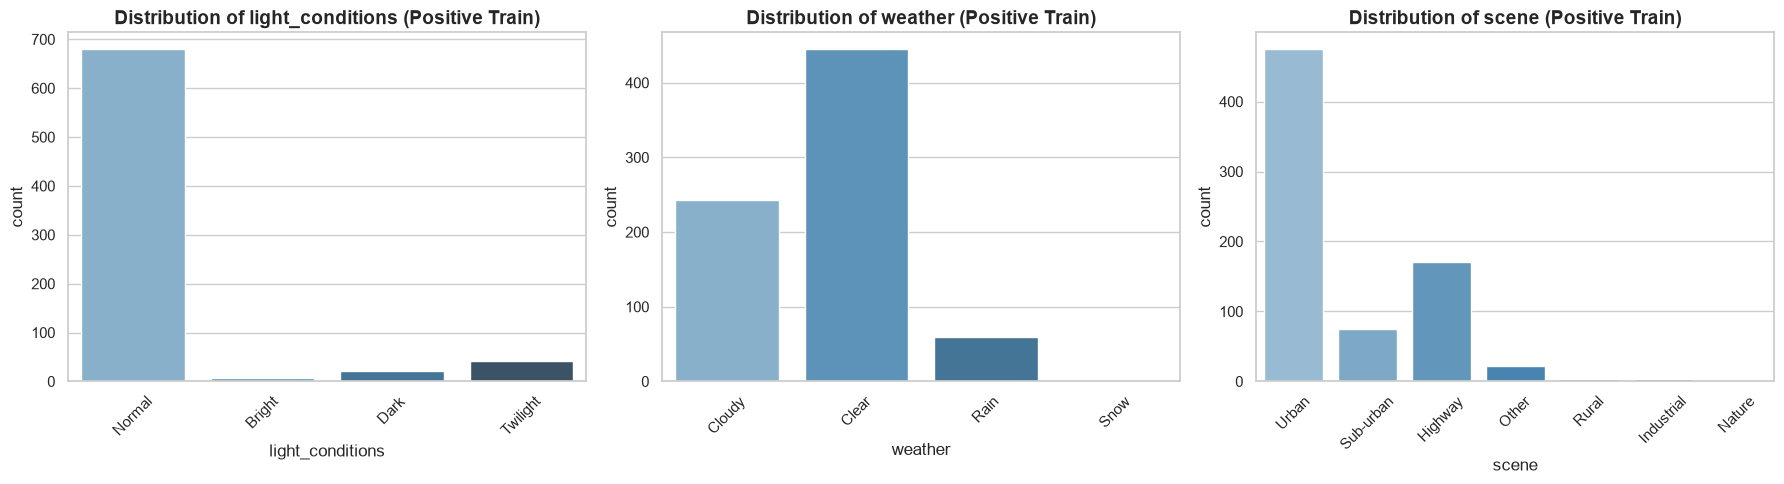

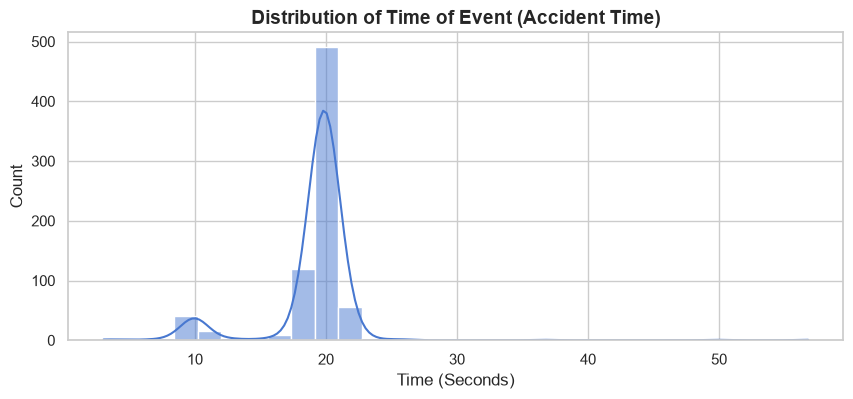

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

# Combine positive and negative for leakage audit
df_pos = prepared_metadata['train/positive/metadata.csv']
df_neg = prepared_metadata['train/negative/metadata.csv']
df_all_train = pd.concat([df_pos, df_neg])

# --- 1. METADATA LEAKAGE AUDIT ---
print("========== METADATA LEAKAGE AUDIT ==========")
for col in ['light_conditions', 'weather', 'scene']:
    leakage_check = df_all_train.groupby(col)['label'].mean().sort_values(ascending=False)
    print(f"\nProbability of Accident (Label=1) given {col}:")
    print(leakage_check)

# --- 2. DISTRIBUTION PLOTS (Fixed Warnings) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(['light_conditions', 'weather', 'scene']):
    sns.countplot(data=df_pos, x=col, ax=axes[i], hue=col, palette="Blues_d", legend=False)
    axes[i].set_title(f'Distribution of {col} (Positive Train)')
    axes[i].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# --- 3. TIME OF EVENT PLOT ---
plt.figure(figsize=(10, 4))
sns.histplot(data=metadata_dfs['train/positive/metadata.csv'], x='time_of_event', bins=30, kde=True)
plt.title('Distribution of Time of Event (Accident Time)')
plt.xlabel('Time (Seconds)')
plt.show()

In [48]:
import hashlib
import cv2
import os
from huggingface_hub import hf_hub_download

# 1. Handle Missing Values (Impute missing weather with the mode)
for key, df in prepared_metadata.items():
    if df['weather'].isnull().any():
        mode_weather = df['weather'].mode()[0]
        df['weather'] = df['weather'].fillna(mode_weather)
        print(f"Filled missing weather in {key} with '{mode_weather}'")

# 2. Finding Duplicate Videos & Corrupted Videos
def get_file_hash(filepath):
    hasher = hashlib.md5()
    with open(filepath, 'rb') as f:
        for chunk in iter(lambda: f.read(4096), b""):
            hasher.update(chunk)
    return hasher.hexdigest()

print("\n--- Running Data Quality & Duration Checks on Sample Videos ---")
os.makedirs("data/quality_check", exist_ok=True)

# Grab two sample videos to actually test
sample_videos = [
    f"train/positive/{prepared_metadata['train/positive/metadata.csv']['file_name'].iloc[0]}",
    f"train/negative/{prepared_metadata['train/negative/metadata.csv']['file_name'].iloc[0]}"
]

seen_hashes = {}
for vpath in sample_videos:
    local_path = hf_hub_download(repo_id="nexar-ai/nexar_collision_prediction", repo_type="dataset", filename=vpath, local_dir="data/quality_check")
    
    # Check for corruption & Calculate Duration
    cap = cv2.VideoCapture(local_path)
    if not cap.isOpened():
        print(f"❌ CORRUPTED VIDEO: {vpath}")
    else:
        fps = cap.get(cv2.CAP_PROP_FPS)
        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        duration = frame_count / fps if fps > 0 else 0
        print(f"✅ Video opens fine: {vpath} | Duration: {duration:.2f} seconds")
    cap.release()
    
    # Check for duplicates
    file_hash = get_file_hash(local_path)
    if file_hash in seen_hashes:
        print(f"⚠️ DUPLICATE FOUND: {vpath} matches {seen_hashes[file_hash]}")
    else:
        seen_hashes[file_hash] = vpath

Filled missing weather in train/negative/metadata.csv with 'Clear'
Filled missing weather in train/positive/metadata.csv with 'Clear'

--- Running Data Quality & Duration Checks on Sample Videos ---
✅ Video opens fine: train/positive/00822.mp4 | Duration: 40.47 seconds
✅ Video opens fine: train/negative/01924.mp4 | Duration: 40.00 seconds


In [49]:
from sklearn.model_selection import train_test_split

# train_test_split will crash if a category in stratify_col has only 1 row.
counts = representative_train['stratify_col'].value_counts()
if counts.min() < 2:
    print("⚠️ Found rare categories with only 1 sample. Grouping them into 'Rare' to prevent crash...")
    rare_classes = counts[counts < 2].index
    representative_train['stratify_col'] = representative_train['stratify_col'].replace(rare_classes, 'Rare_Combo')

# ==========================================
# 1. Perform the 80/20 Stratified Split
# ==========================================
final_train, final_val = train_test_split(
    representative_train,
    test_size=0.2,  # type: ignore
    stratify=representative_train['stratify_col'],
    random_state=42 # type: ignore
)

# ==========================================
# 2. Safely drop helper columns
# ==========================================
cols_to_drop = ['stratify_col', 'time_bin']
final_train = final_train.drop(columns=cols_to_drop, errors='ignore')
final_val = final_val.drop(columns=cols_to_drop, errors='ignore')

# ==========================================
# 3. Verification
# ==========================================
print(f"✅ Final Train Size: {len(final_train)}")
print(f"✅ Final Validation Size: {len(final_val)}")
print(f"Train Labels: {final_train['label'].value_counts().to_dict()}")
print(f"Val Labels:   {final_val['label'].value_counts().to_dict()}")

# Verify no overlap (Ensuring zero data leakage)
overlap = set(final_train['file_name']).intersection(set(final_val['file_name']))
print(f"Overlap check (must be empty): {overlap}")

✅ Final Train Size: 360
✅ Final Validation Size: 90
Train Labels: {1: 183, 0: 177}
Val Labels:   {1: 45, 0: 45}
Overlap check (must be empty): set()


In [50]:
from sklearn.model_selection import GroupShuffleSplit

# Split the representative data into 80% Train and 20% Validation
# We use 'file_name' as the group to prevent the same video from being in both sets
gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)
train_idx, val_idx = next(gss.split(representative_train, groups=representative_train['file_name']))

final_train = representative_train.iloc[train_idx]
final_val = representative_train.iloc[val_idx]

# ✅ Drop the helper column so it can't leak into features later
final_train = final_train.drop(columns=['stratify_col'])
final_val   = final_val.drop(columns=['stratify_col'])

print(f"Final Train Size: {len(final_train)}")
print(f"Final Validation Size: {len(final_val)}")

# Verify no overlap
overlap = set(final_train['file_name']).intersection(set(final_val['file_name']))
print(f"Overlap check (should be empty): {overlap}")

# ✅ Optional: verify the column is really gone
assert 'stratify_col' not in final_train.columns
assert 'stratify_col' not in final_val.columns
print("final_train columns:", list(final_train.columns))
print("final_val columns:  ", list(final_val.columns))

Final Train Size: 360
Final Validation Size: 90
Overlap check (should be empty): set()
final_train columns: ['file_name', 'light_conditions', 'weather', 'scene', 'label', 'video_path']
final_val columns:   ['file_name', 'light_conditions', 'weather', 'scene', 'label', 'video_path']


In [51]:
import os

# 1. Save Train and Validation sets
os.makedirs("data/processed", exist_ok=True)

final_train.to_csv("data/processed/final_train.csv", index=False)
final_val.to_csv("data/processed/final_val.csv", index=False)

print("✅ Saved final_train.csv and final_val.csv")

# 2. Prepare the Test Sets (Public and Private)
test_frames = []

for split in ['test-public', 'test-private']:
    for label_type in ['positive', 'negative']:
        path = f'{split}/{label_type}/metadata.csv'
        if path in prepared_metadata:
            df = prepared_metadata[path].copy()
            # Add subset and absolute video path
            df['subset'] = split
            df['video_path'] = f'{split}/{label_type}/' + df['file_name']
            test_frames.append(df)

final_test = pd.concat(test_frames).reset_index(drop=True)

# Save Test set
final_test.to_csv("data/processed/final_test.csv", index=False)
print("✅ Saved final_test.csv")

# 3. Final Sanity Check
print("\n========== FINAL DATASET SHAPES ==========")
print(f"Train: {final_train.shape} | Labels: {final_train['label'].value_counts().to_dict()}")
print(f"Val:   {final_val.shape} | Labels: {final_val['label'].value_counts().to_dict()}")
print(f"Test:  {final_test.shape} | Labels: {final_test['label'].value_counts().to_dict()}")

print("\n========== FINAL COLUMNS ==========")
print(list(final_train.columns))

✅ Saved final_train.csv and final_val.csv
✅ Saved final_test.csv

========== FINAL DATASET SHAPES ==========
Train: (360, 6) | Labels: {1: 180, 0: 180}
Val:   (90, 6) | Labels: {1: 48, 0: 42}
Test:  (1344, 7) | Labels: {1: 672, 0: 672}

========== FINAL COLUMNS ==========
['file_name', 'light_conditions', 'weather', 'scene', 'label', 'video_path']


========== CLASS BALANCE ACROSS SPLITS ==========


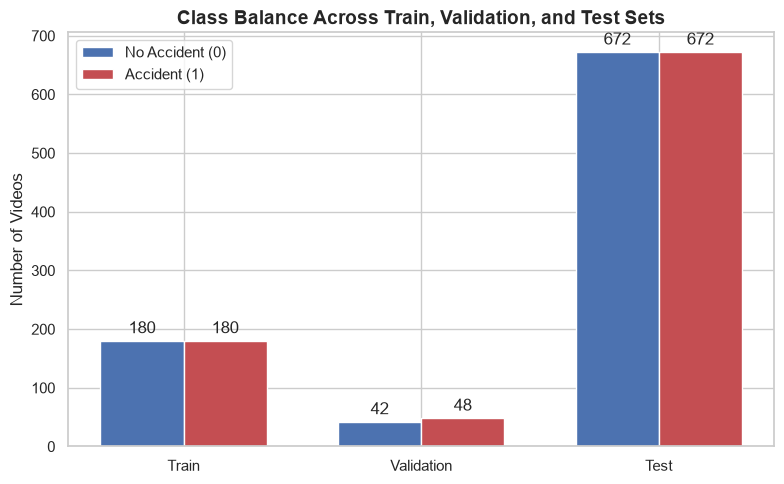


========== METADATA LEAKAGE AUDIT ==========


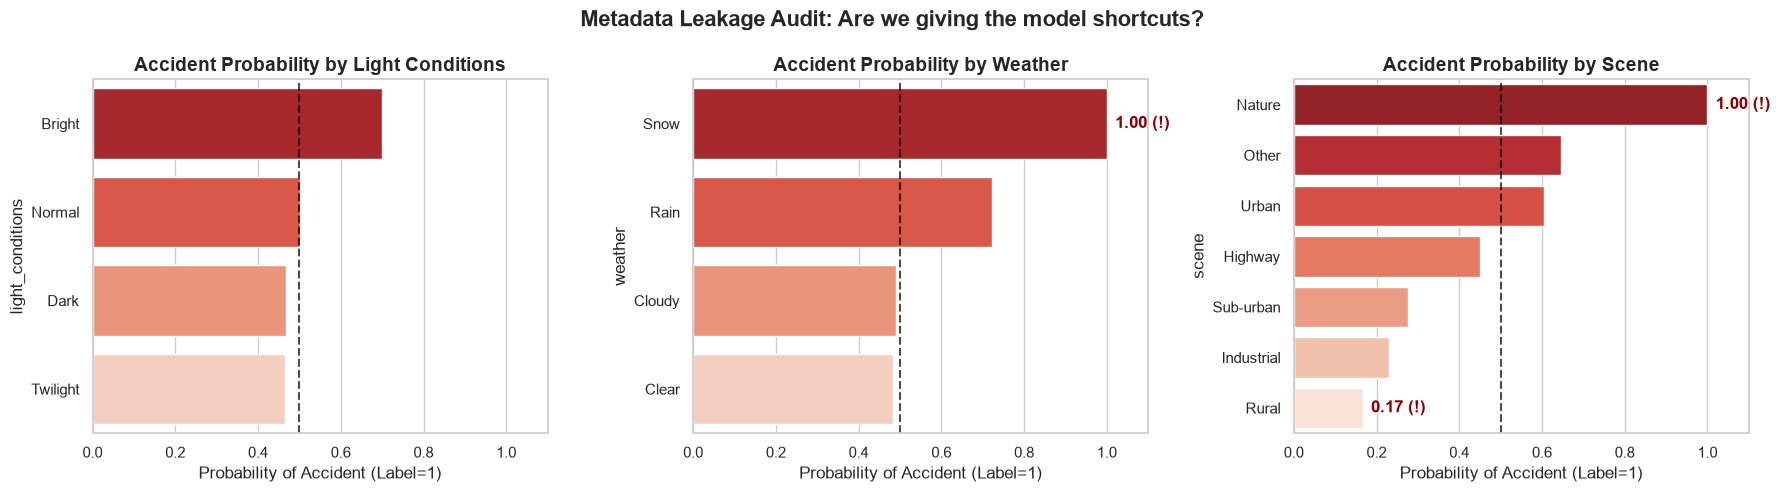


========== POSITIVE VS NEGATIVE ENVIRONMENT DISTRIBUTIONS ==========


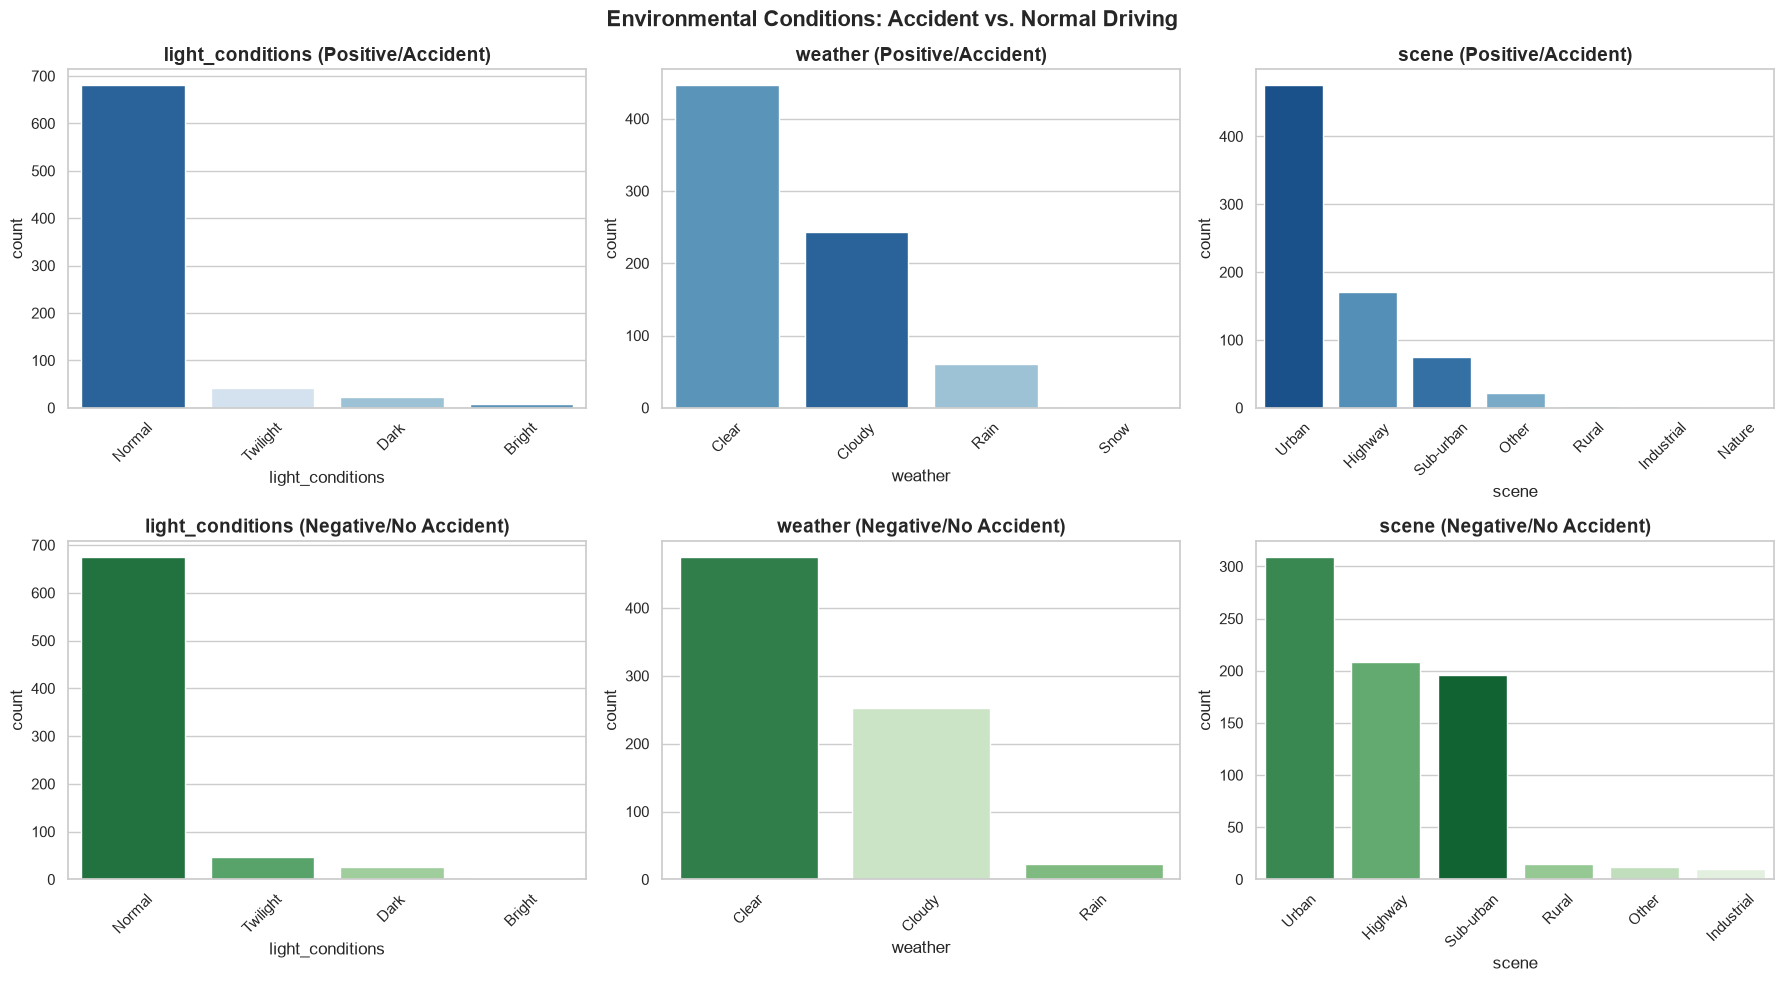


========== TIME OF EVENT DISTRIBUTION ==========


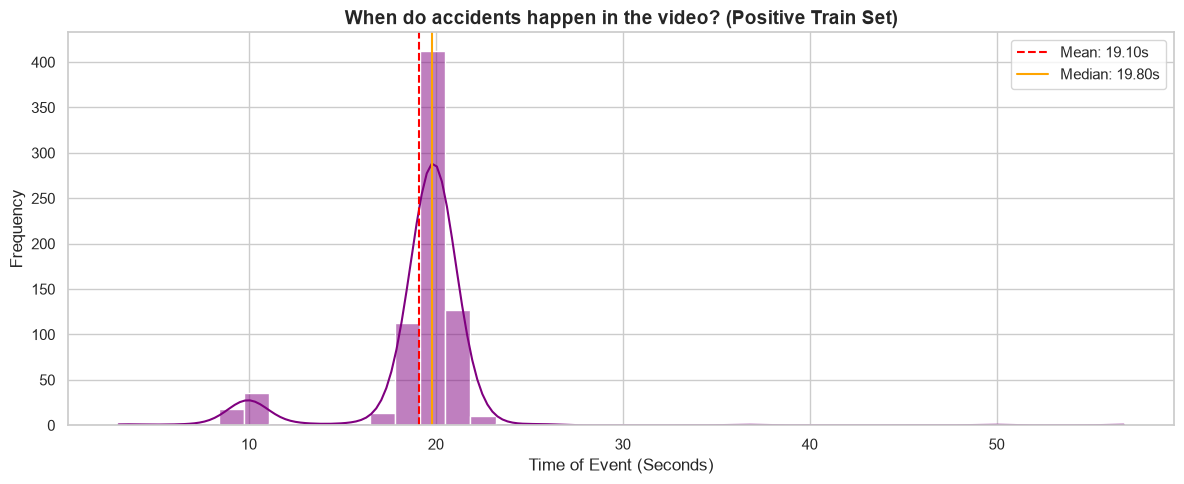

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Set a beautiful, professional style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.size': 12, 'axes.titlesize': 14, 'axes.titleweight': 'bold'})

# ==========================================
# 1. CLASS BALANCE ACROSS SPLITS
# ==========================================
print("========== CLASS BALANCE ACROSS SPLITS ==========")
splits = ['Train', 'Validation', 'Test']
counts_0 = [sum(final_train['label']==0), sum(final_val['label']==0), sum(final_test['label']==0)]
counts_1 = [sum(final_train['label']==1), sum(final_val['label']==1), sum(final_test['label']==1)]

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(splits))
width = 0.35

rects1 = ax.bar(x - width/2, counts_0, width, label='No Accident (0)', color='#4C72B0')
rects2 = ax.bar(x + width/2, counts_1, width, label='Accident (1)', color='#C44E52')

ax.set_ylabel('Number of Videos')
ax.set_title('Class Balance Across Train, Validation, and Test Sets')
ax.set_xticks(x)
ax.set_xticklabels(splits)
ax.legend()
ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)
plt.tight_layout()
plt.show()

# ==========================================
# 2. METADATA LEAKAGE AUDIT (Visualized)
# ==========================================
print("\n========== METADATA LEAKAGE AUDIT ==========")
df_pos = prepared_metadata['train/positive/metadata.csv']
df_neg = prepared_metadata['train/negative/metadata.csv']
df_all_train = pd.concat([df_pos, df_neg])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(['light_conditions', 'weather', 'scene']):
    leakage_check = df_all_train.groupby(col)['label'].mean().sort_values(ascending=False)
    
    # FIX 1: Added hue and legend=False to fix the Seaborn FutureWarning
    sns.barplot(x=leakage_check.values, y=leakage_check.index, ax=axes[i], 
                hue=leakage_check.index, palette="Reds_r", legend=False)
    
    axes[i].axvline(0.5, color='black', linestyle='--', alpha=0.7)
    axes[i].set_title(f'Accident Probability by {col.replace("_", " ").title()}')
    axes[i].set_xlabel('Probability of Accident (Label=1)')
    axes[i].set_xlim(0, 1.1)
    
    # FIX 2: Replaced the ⚠️ emoji with "(!)" so the Windows font can display it
    for j, v in enumerate(leakage_check.values):
        if v > 0.8 or v < 0.2:
            axes[i].text(v + 0.02, j, f"{v:.2f} (!)", va='center', fontweight='bold', color='darkred')

plt.suptitle('Metadata Leakage Audit: Are we giving the model shortcuts?', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================
# 3. POSITIVE VS NEGATIVE DISTRIBUTIONS
# ==========================================
print("\n========== POSITIVE VS NEGATIVE ENVIRONMENT DISTRIBUTIONS ==========")
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for i, col in enumerate(['light_conditions', 'weather', 'scene']):
    # Positive Plot (FIXED)
    sns.countplot(data=df_pos, x=col, ax=axes[0, i], order=df_pos[col].value_counts().index, 
                  hue=col, palette="Blues_r", legend=False)
    axes[0, i].set_title(f'{col} (Positive/Accident)')
    axes[0, i].tick_params(axis='x', rotation=45)
    
    # Negative Plot (FIXED)
    sns.countplot(data=df_neg, x=col, ax=axes[1, i], order=df_neg[col].value_counts().index, 
                  hue=col, palette="Greens_r", legend=False)
    axes[1, i].set_title(f'{col} (Negative/No Accident)')
    axes[1, i].tick_params(axis='x', rotation=45)
plt.suptitle('Environmental Conditions: Accident vs. Normal Driving', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================
# 4. TIME OF EVENT DISTRIBUTION
# ==========================================
print("\n========== TIME OF EVENT DISTRIBUTION ==========")
plt.figure(figsize=(12, 5))
sns.histplot(data=metadata_dfs['train/positive/metadata.csv'], x='time_of_event', bins=40, kde=True, color='purple')
mean_time = metadata_dfs['train/positive/metadata.csv']['time_of_event'].mean()
median_time = metadata_dfs['train/positive/metadata.csv']['time_of_event'].median()
plt.axvline(mean_time, color='red', linestyle='--', label=f'Mean: {mean_time:.2f}s')
plt.axvline(median_time, color='orange', linestyle='-', label=f'Median: {median_time:.2f}s')

plt.title('When do accidents happen in the video? (Positive Train Set)')
plt.xlabel('Time of Event (Seconds)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()